# Interference - Single Slit

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch04/ch04-02.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        print("ipympl installed. Colab will restart the runtime once; when it has, run this cell again.")
        get_ipython().kernel.do_shutdown(restart=True)
    from google.colab import output
    output.enable_custom_widget_manager()

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm

In [2]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)



## Define parameters

In [3]:
# --- Parameters ---
L1 = 2 * 10**6       # Distance to screen in microns
wavelength1 = 0.632  # Wavelength in microns
a1 = 40              # slit width in microns


# --- Data Generation ---
# Generate x values from -10^5 to 10^5
numpointsx1 = 512
x1 = np.linspace(-1e5,1e5,num=numpointsx1)
intensity1 = (np.sin(np.pi*a1/wavelength1*x1/np.sqrt(x1**2+L1**2))/(np.pi*a1/wavelength1*x1/np.sqrt(x1**2+L1**2)))**2
# Fix NaN at center if x hits 0 exactly
intensity1 = np.nan_to_num(intensity1, nan=1.0)

## Plot

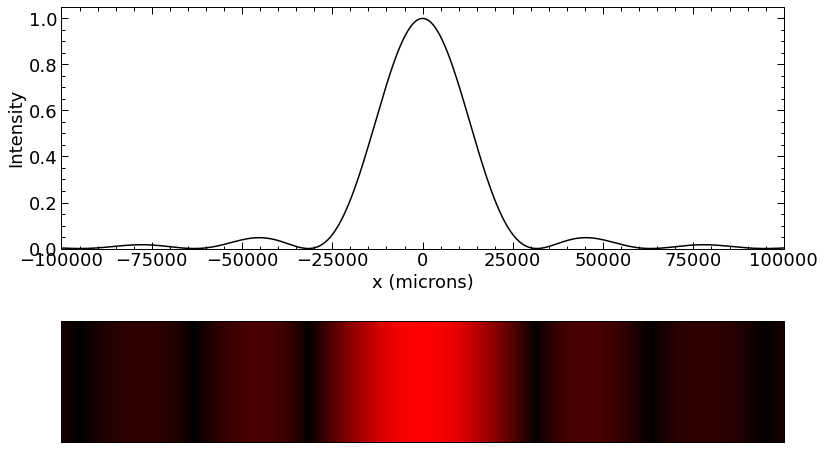

In [4]:
# --- Plotting ---
textsize1 = 18
#Sets the default font style and size in plots
font = {'family' : 'sans-serif',
        'size'   : textsize1}

plt.rc('font', **font)

fig1, (ax1, ax2) = plt.subplots(2, 1, figsize=(8*1.618,8), gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.4})

# 1. Line Plot
ax1.plot(x1, intensity1, color='k', linewidth=1.5)
ax1.set_xlim(-10**5, 10**5)
ax1.set_ylim(0, 1.05)
ax1.set_xlabel("x (microns)")
ax1.set_ylabel("Intensity")
ax1.minorticks_on()
ax1.tick_params(which='both',direction="in",width=1)
ax1.tick_params(which='major',length=7)
ax1.tick_params(which='minor',length=3.5)
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')

# 2. Density Plot (Simulating the visual pattern)
# Create a custom Black-to-Green colormap to match RGBColor[0, #, 0]
colors = [(0, 0, 0), (1, 0, 0)] # Black to Red
laser_cmap = LinearSegmentedColormap.from_list("laser_red", colors)

# Expand the 1D intensity array into 2D for image plotting
# We tile it vertically to give it height
intensity1_2d = np.tile(intensity1, (100, 1))

# Plot using imshow
# aspect='auto' allows the plot to stretch to fill the figure width
# extent sets the axis labels to match the real coordinates
ax2.imshow(intensity1_2d, extent=[-10**5, 10**5, -1, 1], 
           aspect='auto', cmap=laser_cmap,
           norm=PowerNorm(gamma=0.4))

ax2.set_xticks([]) # Remove x ticks for the density plot
ax2.set_yticks([]) # Remove y ticks as they are arbitrary
ax2.tick_params(direction='in')

plt.show()

## Animation

In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm
import ipywidgets as widgets
from IPython.display import display

# --- 1. Global Styling & Parameters ---
plot_params = {
    'font.size': 12, 
    'font.family': 'sans-serif',
    'axes.linewidth': 1.0,
    'lines.linewidth': 2.5,
}
plt.rcParams.update(plot_params)

# Constants
L1 = 2 * 10**6      # Distance to screen (microns)
NUM_POINTS = 512    # Resolution
X_RANGE = 1e5       # microns

# Data Generation (Global X axis)
x1 = np.linspace(-X_RANGE, X_RANGE, num=NUM_POINTS)

# --- 2. Helper: Wavelength to RGB Color ---
def wavelength_to_rgb(wavelength, gamma=0.8):
    wl = float(wavelength)
    if 380 <= wl <= 440:
        R = -(wl - 440) / (440 - 380); G = 0.0; B = 1.0
    elif 440 < wl <= 490:
        R = 0.0; G = (wl - 440) / (490 - 440); B = 1.0
    elif 490 < wl <= 510:
        R = 0.0; G = 1.0; B = -(wl - 510) / (510 - 490)
    elif 510 < wl <= 580:
        R = (wl - 510) / (580 - 510); G = 1.0; B = 0.0
    elif 580 < wl <= 645:
        R = 1.0; G = -(wl - 645) / (645 - 580); B = 0.0
    elif 645 < wl <= 750:
        R = 1.0; G = 0.0; B = 0.0
    else:
        R = 0.0; G = 0.0; B = 0.0
    
    # Intensity drop-off near edges of vision
    if wl > 700: alpha = 0.3 + 0.7 * (750 - wl) / (750 - 700)
    elif wl < 420: alpha = 0.3 + 0.7 * (wl - 380) / (420 - 380)
    else: alpha = 1.0
    return (R * alpha, G * alpha, B * alpha)

# --- 3. Figure Initialization ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), 
                               gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.3})

# Remove "Figure 1" Header
fig.canvas.header_visible = False
fig.canvas.footer_visible = False

# Initial Calculation (Single Slit Diffraction)
init_a = 40.0    # slit width
init_w = 0.632   # wavelength
denom = np.pi * init_a / init_w * x1 / np.sqrt(x1**2 + L1**2)
intensity = (np.sin(denom) / denom)**2
intensity = np.nan_to_num(intensity, nan=1.0) # Handle center singularity
init_color = wavelength_to_rgb(init_w * 1000)

# 1. Line Plot
line_plot, = ax1.plot(x1, intensity, color=init_color, linewidth=2)
ax1.set_xlim(-X_RANGE, X_RANGE)
ax1.set_ylim(0, 1.05)
ax1.set_ylabel("Intensity")
ax1.minorticks_on()
ax1.tick_params(which='both', direction="in", width=1, top=True, right=True)

# 2. Density Plot
laser_cmap = LinearSegmentedColormap.from_list("laser", [(0,0,0), init_color])
intensity_2d = np.tile(intensity, (100, 1))

# --- FIX APPLIED HERE: vmin/vmax moved inside PowerNorm ---
img_plot = ax2.imshow(intensity_2d, extent=[-X_RANGE, X_RANGE, -1, 1], 
                      aspect='auto', cmap=laser_cmap,
                      norm=PowerNorm(gamma=0.4, vmin=0, vmax=1)) 

ax2.set_xlabel("x (microns)")
ax2.set_yticks([])
ax2.tick_params(direction='in')

plt.tight_layout()

# --- 4. Logic & Updates ---
def update_simulation(a_val, w_val):
    # Physics: Single Slit Diffraction
    u = (np.pi * a_val * x1) / (w_val * np.sqrt(x1**2 + L1**2))
    
    with np.errstate(divide='ignore', invalid='ignore'):
        new_intensity = (np.sin(u) / u)**2
    new_intensity = np.nan_to_num(new_intensity, nan=1.0)
    
    # Update Line
    line_plot.set_ydata(new_intensity)
    
    # Update Image
    img_plot.set_data(np.tile(new_intensity, (100, 1)))
    
    # Update Colors
    rgb = wavelength_to_rgb(w_val * 1000)
    line_plot.set_color(rgb)
    new_cmap = LinearSegmentedColormap.from_list("laser", [(0,0,0), rgb])
    img_plot.set_cmap(new_cmap)
    
    fig.canvas.draw_idle()

# --- 5. Widgets ---
def on_change(change):
    update_simulation(a_slider.value, w_slider.value)

a_slider = widgets.FloatSlider(value=40, min=10, max=200, step=1, description='Slit Width (a)')
w_slider = widgets.FloatSlider(value=0.632, min=0.400, max=0.700, step=0.001, description='Wavelength')

a_slider.observe(on_change, names='value')
w_slider.observe(on_change, names='value')

display(widgets.VBox([a_slider, w_slider]))

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch04/ch04-02_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch04/ch04-02.html) (direct link: [ch04-02_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch04/ch04-02_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.